# Dataset and DataLoader: step by step


Pipeline: `image file -> transforms -> ImageFolder -> DataLoader -> batches`

## 1. Imports

In [1]:
import sys
sys.path.append("..")

from pathlib import Path

import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from src.utils import IMAGE_SIZE, MEAN, STD, TEST_DIR, TRAIN_DIR, VAL_DIR

print("torch:", torch.__version__)

torch: 2.14.1


## 2. Check constants and folders

Before building anything, make sure the folders exist and the constants are what we expect.

In [2]:
print("IMAGE_SIZE:", IMAGE_SIZE)
print("MEAN:", MEAN)
print("STD:", STD)

for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print(f"{split_dir.name:5s} | exists: {split_dir.exists()} | classes: {sorted(p.name for p in split_dir.iterdir() if p.is_dir())}")

IMAGE_SIZE: 128
MEAN: (0.5, 0.5, 0.5)
STD: (0.5, 0.5, 0.5)
train | exists: True | classes: ['bibimbap', 'fried_rice']
val   | exists: True | classes: ['bibimbap', 'fried_rice']
test  | exists: True | classes: ['bibimbap', 'fried_rice']


## 3. Transforms

**Train transforms** (with augmentation):
1. `Resize`: all images get the same size
2. `RandomHorizontalFlip(p=0.5)`: with 50% chance the image is mirrored
3. `RandomRotation(10)`: rotate randomly between -10 and +10 degrees
4. `ToTensor`: PIL image `(H, W, C)`, values 0-255 -> tensor `(C, H, W)`, values 0-1
5. `Normalize`: `x_new = (x - mean) / std` for each channel

**Eval transforms** (validation and test): the same, but **without** the random steps.

Why? Augmentation creates slightly different versions of the same image, so the model sees more variety and overfits less.
Validation and test must stay fixed, otherwise the score would change randomly between runs.

In [3]:
def get_train_transforms():
    """Training transforms: resize, small augmentation, tensor, normalize."""
    return transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ])


def get_eval_transforms():
    """Validation and test transforms without augmentation."""
    return transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ])


print(get_train_transforms())
print()
print(get_eval_transforms())

Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)

Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)


## 4. See the transforms in action

We load one raw image (no transform, so it stays a PIL image) and apply the transforms to it.

- Train transform is random: every call gives a different result
- Eval transform is fixed: every call gives the same result

`denormalize` undoes `Normalize` so the image can be shown with correct colors: `x = x * std + mean`.

Raw image: <class 'PIL.Image.Image'> (384, 512) | label: bibimbap


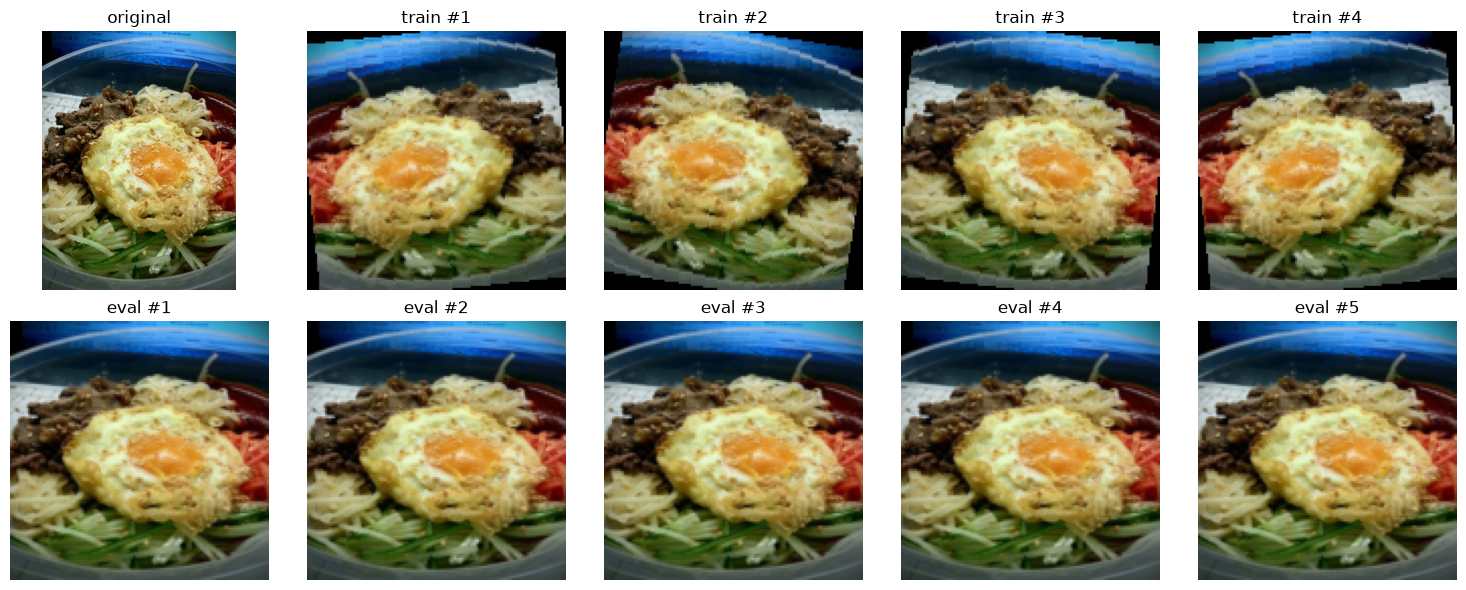

In [26]:
def denormalize(img):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (img * std + mean).clamp(0, 1)


raw_ds = datasets.ImageFolder(root=TRAIN_DIR)   # no transform -> PIL image
raw_img, raw_label = raw_ds[0]
print("Raw image:", type(raw_img), raw_img.size, "| label:", raw_ds.classes[raw_label])

train_tf = get_train_transforms()
eval_tf = get_eval_transforms()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

axes[0, 0].imshow(raw_img)
axes[0, 0].set_title("original")

for i in range(1, 5):
    out = train_tf(raw_img)   # different every time
    axes[0, i].imshow(denormalize(out).permute(1, 2, 0))
    axes[0, i].set_title(f"train #{i}")

for i in range(5):
    out = eval_tf(raw_img)    # the same every time
    axes[1, i].imshow(denormalize(out).permute(1, 2, 0))
    axes[1, i].set_title(f"eval #{i + 1}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. ImageFolder

`ImageFolder` reads `root/<class_name>/image.jpg`. The **folder name becomes the label** (alphabetical order).
Train gets the augmentation transforms, val and test get the eval transforms.

In [5]:
def create_imagefolder_dataset(data_dir: Path, transform):
    """Create an ImageFolder dataset from a split directory."""
    return datasets.ImageFolder(root=data_dir, transform=transform)


train_dataset = create_imagefolder_dataset(TRAIN_DIR, get_train_transforms())
val_dataset = create_imagefolder_dataset(VAL_DIR, get_eval_transforms())
test_dataset = create_imagefolder_dataset(TEST_DIR, get_eval_transforms())

print("Train size:", len(train_dataset))
print("Val size:", len(val_dataset))
print("Test size:", len(test_dataset))
print("Class to index:", train_dataset.class_to_idx)

Train size: 1200
Val size: 300
Test size: 500
Class to index: {'bibimbap': 0, 'fried_rice': 1}


## 6. Check that the labels match in all splits

If `class_to_idx` were different in train and val, the model would learn one mapping and be tested on another.

In [27]:
print("train == val:", train_dataset.class_to_idx == val_dataset.class_to_idx)
print("train == test:", train_dataset.class_to_idx == test_dataset.class_to_idx)

train == val: True
train == test: True


## 7. One sample from the dataset

`dataset[i]` returns `(tensor, label)`.

In [7]:
x, y = train_dataset[0]
print("Tensor shape:", x.shape)   # (C, H, W)
print("Tensor dtype:", x.dtype)
print("Value range:", round(x.min().item(), 2), "to", round(x.max().item(), 2))
print("Label:", y, "->", train_dataset.classes[y])

Tensor shape: torch.Size([3, 128, 128])
Tensor dtype: torch.float32
Value range: -1.0 to 0.96
Label: 0 -> bibimbap


## 8. DataLoader

`DataLoader` groups samples into batches.

- `shuffle=True` only for train: a new random order every epoch
- `shuffle=False` for val and test: the order does not matter for evaluation
- `num_workers=0`: the safest option on Mac

In [28]:
BATCH_SIZE = 16

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 75
Val batches: 19
Test batches: 32


## 9. Check one batch

Expected image shape: `[batch, 3, IMAGE_SIZE, IMAGE_SIZE]`. Expected label shape: `[batch]`.

In [9]:
images, labels = next(iter(train_loader))

print("Sample batch image shape:", images.shape)
print("Sample batch label shape:", labels.shape)
print("Labels:", labels)
print("Class names:", train_dataset.classes)

Sample batch image shape: torch.Size([16, 3, 128, 128])
Sample batch label shape: torch.Size([16])
Labels: tensor([1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0])
Class names: ['bibimbap', 'fried_rice']


## 10. Visualize a batch

Shuffle is on, so run this cell several times: each time you will see different images.

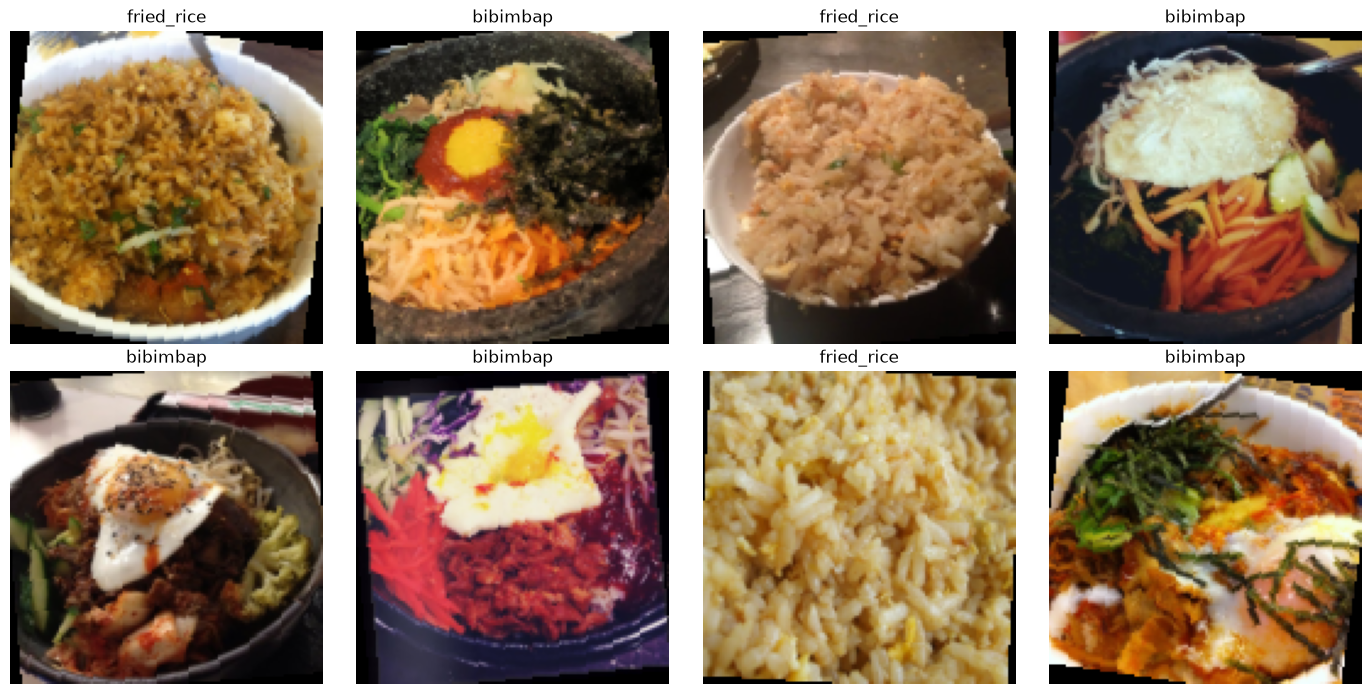

In [12]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, label in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(train_dataset.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 11. Check shuffle behavior

Train loader (shuffle=True): the first batch should be different every time.
Val loader (shuffle=False): the first batch should be the same every time.

In [16]:
_, train_a = next(iter(train_loader))
_, train_b = next(iter(train_loader))
print("Train batch A:", train_a.tolist())
print("Train batch B:", train_b.tolist())

_, val_a = next(iter(val_loader))
_, val_b = next(iter(val_loader))
print("Val batch A:", val_a.tolist())
print("Val batch B:", val_b.tolist())
print("Val batches identical:", torch.equal(val_a, val_b))

Train batch A: [0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1]
Train batch B: [0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1]
Val batch A: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Val batch B: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Val batches identical: True


## 12. Everything in one function

This is the same function as `create_dataloaders` in `src/dataset.py`. If this cell works, the script will work too.

In [17]:
def create_dataloaders(batch_size: int = 16):
    """Create train, validation, and test DataLoaders."""
    train_dataset = create_imagefolder_dataset(TRAIN_DIR, get_train_transforms())
    val_dataset = create_imagefolder_dataset(VAL_DIR, get_eval_transforms())
    test_dataset = create_imagefolder_dataset(TEST_DIR, get_eval_transforms())

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    class_names = train_dataset.classes

    sample_images, sample_labels = next(iter(train_loader))
    print(f"Sample batch image shape: {sample_images.shape}")
    print(f"Sample batch label shape: {sample_labels.shape}")
    print("Class names:", class_names)

    return train_loader, val_loader, test_loader, class_names


train_loader, val_loader, test_loader, class_names = create_dataloaders(batch_size=16)

Sample batch image shape: torch.Size([16, 3, 128, 128])
Sample batch label shape: torch.Size([16])
Class names: ['bibimbap', 'fried_rice']
